## short-term trading v2

In [1]:
import os
import datetime as dt

from dotenv import load_dotenv
from pathlib import Path

import json
import time
from urllib.parse import urljoin, urlencode
import requests

import numpy as np
import pandas as pd

import plotly
import plotly.graph_objs as go
import plotly.express as px
import seaborn as sns
import matplotlib.pyplot as plt

from Modules.utility import Utility
from Modules.show_plot import ShowPlot
from Modules.reques_api import RequestApi
from Modules.get_market_data import GetMarketData
from Modules.stock_prices_and_market_data import ClassStockPricesMarketData
from Modules.financial import Financial
from Modules.pdf_url_to_markdown import PDFUrlToMarkdown
from Modules.webpage_to_markdown import WebpageToMarkdown
from Modules.compute_fibonacci_extension import ComputeFibonacciExtension

In [2]:
# FRED API key for accessing Federal Reserve Economic Data
FRED_API_KEY = os.getenv("FRED_API_KEY")
# Output directory for storing downloaded data
API_BASE_URL = os.getenv("API_BASE_URL", "http://localhost:8000")
request_api = RequestApi(API_BASE_URL)
get_market_data = GetMarketData(Path('/workspace/data'))
utility = Utility()
stock_prices_market_data = ClassStockPricesMarketData()
financial = Financial()
# URLからPDFをダウンロードしてMarkdownに変換するクラスのインスタンスを作成
pdf_to_md = PDFUrlToMarkdown()
# WEBページをMarkdownに変換する関数
webpage_to_markdown = WebpageToMarkdown()
# Fibonacciエクステンションを計算するクラスのインスタンスを作成
fibonacci_extension = ComputeFibonacciExtension()

In [3]:
# Date range for fetching API s
start = '2022-01-01'
end = dt.datetime.now().strftime('%Y-%m-%d')
output_dir = Path("/workspace/data/")
output_dir.mkdir(parents=True, exist_ok=True)
# Define sector ETFs, benchmarks, and commodities for analysis
sector_etfs = {
    "oil": "XOP",
    "uranium": "URNM",
    "gold": "GDX",
    "silver": "SIL",
    "copper": "COPX",
    "critical_minerals": "REMX",
}
# Define benchmarks for analysis
benchmarks = {
    "SP500": "SPY",
    "NASDAQ100": "QQQ",
    "RUSSELL2000": "IWM"
}
# Define commodities for analysis
commodities = {
    "WTI": "CL=F",
    "BRENT": "BZ=F",
    "NATGAS": "NG=F",
    "GOLD": "GC=F",
    "SILVER": "SI=F",
    "COPPER": "HG=F",
    "URANIUM": "SRUUF"
}

#### Functions

In [4]:
def get_stock_timeseries_data(
    start_date: str,
    end_date: str,
    code: str,
    market: str | None,
) -> pd.DataFrame:
    # Fetch market data from the API based on the provided parameters
    response = request_api.update_stock_timeseries_data(
        code=code,
        market=market,
        start=start_date,
        end=end_date
    )
    # Retrieve the time series data from the API
    if response is None:
        return pd.DataFrame()
    # If the response is valid, proceed to fetch the time series data
    df = request_api.get_stock_time_series_data(
        code=code,
        market=market,
        start=start_date,
        end=end_date
    )
    df["date"] = pd.to_datetime(df["date"])
    return df

In [5]:
def get_commodity_timeseries_data(
    start_date: str,
    end_date: str,
    code: str,
    market: str | None,
) -> pd.DataFrame:
    # Fetch market data from the API based on the provided parameters
    response = request_api.update_commodity_timeseries_data(
        code=code,
        market=market,
        start=start_date,
        end=end_date
    )
    # Retrieve the time series data from the API
    if response is None:
        return pd.DataFrame()
    # If the response is valid, proceed to fetch the time series data
    df = request_api.get_commodity_time_series_data(
        code=code,
        market=market,
        start=start_date,
        end=end_date
    )
    df["date"] = pd.to_datetime(df["date"])
    return df

#### 各サブセクタのデータフレーム取得

In [6]:
sector_dfs: dict[str, pd.DataFrame] = {
    name: get_stock_timeseries_data(
        start_date=start,
        end_date=end,
        code=code,
        market=None,
    )
    for name, code in sector_etfs.items()
}

# 個別に使いたい場合のセクターETFデータフレームの取得
oil_sector_etf_df = sector_dfs["oil"]  # 個別に使いたい場合
uranium_sector_etf_df = sector_dfs["uranium"]  # 個別に使いたい場合
gold_sector_etf_df = sector_dfs["gold"]  # 個別に使いたい場合
silver_sector_etf_df = sector_dfs["silver"]  # 個別に使いたい場合
copper_sector_etf_df = sector_dfs["copper"]  # 個別に使いたい場合
critical_minerals_sector_etf_df = sector_dfs["critical_minerals"]  # 個別に使いたい場合

取得件数: 1417
取得件数: 1417
取得件数: 1417
取得件数: 1417
取得件数: 1417
取得件数: 1417


#### インデクスのデータフレーム取得

In [7]:

benchmark_dfs: dict[str, pd.DataFrame] = {
    name: get_stock_timeseries_data(
        start_date=start,
        end_date=end,
        code=code,
        market=None,
    )
    for name, code in benchmarks.items()
}

# 個別に使いたい場合
sp500_df = benchmark_dfs["SP500"]  # 例: S&P 500
nasdaq_df = benchmark_dfs["NASDAQ100"]  # 例: NASDAQ
russell2000_df = benchmark_dfs["RUSSELL2000"]  # 例: Russell 2000

取得件数: 1417
取得件数: 1417
取得件数: 1417


#### 原資産の時系列をデータフレーム化

In [8]:
commodity_dfs: dict[str, pd.DataFrame] = {
    name: get_commodity_timeseries_data(
        start_date=start,
        end_date=end,
        code=code,
        market=None,
    )
    for name, code in commodities.items()
}

# 個別に使いたい場合のコモディティデータフレームの取得
wti_df = commodity_dfs["WTI"]  # 個別に使いたい場合
brent_df = commodity_dfs["BRENT"]  # 個別に使いたい場合
natural_gas_df = commodity_dfs["NATGAS"]  # 個別に使いたい場合
gold_df = commodity_dfs["GOLD"]  # 個別に使いたい場合
silver_df = commodity_dfs["SILVER"]  # 個別に使いたい場合
copper_df = commodity_dfs["COPPER"]  # 個別に使いたい場合
uranium_df = commodity_dfs["URANIUM"]  # 個別に使いたい場合

取得件数: 1420
取得件数: 1420
取得件数: 1420
取得件数: 1420
取得件数: 1419
取得件数: 1420
取得件数: 1322


#### No.1 データ統合

In [9]:
sector_close = pd.DataFrame({
    name: df.set_index("date")["close"]
    for name, df in sector_dfs.items()
})

benchmark_close = pd.DataFrame({
    name: df.set_index("date")["close"]
    for name, df in benchmark_dfs.items()
})

commodity_close = pd.DataFrame({
    name: df.set_index("date")["close"]
    for name, df in commodity_dfs.items()
})

sector_close = sector_close.sort_index()
benchmark_close = benchmark_close.sort_index()
commodity_close = commodity_close.sort_index()

# 日付ソート
sector_close = sector_close.sort_index()
benchmark_close = benchmark_close.sort_index()
commodity_close = commodity_close.sort_index()

# 前方補完
sector_close = sector_close.ffill()
benchmark_close = benchmark_close.ffill()
commodity_close = commodity_close.ffill()

# 全列で欠損のある行を除去
sector_close = sector_close.dropna()
benchmark_close = benchmark_close.dropna()
commodity_close = commodity_close.dropna()

all_data = pd.concat(
    [
        sector_close.add_prefix("sector_"),
        benchmark_close.add_prefix("benchmark_"),
        commodity_close.add_prefix("commodity_")
    ],
    axis=1
)

all_data = all_data.ffill()

print(all_data.shape)
all_data.tail()

(1421, 16)


/tmp/ipykernel_757/2612706987.py:35: Pandas4Warning: Sorting by default when concatenating all DatetimeIndex is deprecated.  In the future, pandas will respect the default of `sort=False`. Specify `sort=True` or `sort=False` to silence this message. If you see this warnings when not directly calling concat, report a bug to pandas.
  all_data = pd.concat(


,sector_oil,sector_uranium,sector_gold,sector_silver,sector_copper,sector_critical_minerals,benchmark_SP500,benchmark_NASDAQ100,benchmark_RUSSELL2000,commodity_WTI,commodity_BRENT,commodity_NATGAS,commodity_GOLD,commodity_SILVER,commodity_COPPER,commodity_URANIUM
date,,,,,,,,,,,,,,,,
2026-10-20,201.520004,42.779999,85.620003,80.779999,78.150002,53.299999,765.859985,715.250000,271.529999,103.430000,109.129997,3.043,4162.399902,56.740002,6.5390,18.709999
2026-10-21,199.520004,43.669998,86.970001,81.680000,78.230003,53.849998,771.169983,722.219971,276.859985,98.190002,109.269997,3.000,4143.399902,57.250000,6.5060,18.930000
2026-10-22,200.240005,42.500000,83.849998,78.529999,74.809998,51.900002,766.369995,713.609985,274.809998,97.779999,109.919998,2.780,4159.000000,57.000000,6.3755,18.780001
2026-10-23,198.089996,41.330002,81.160004,75.199997,73.080002,51.009998,759.900024,702.200012,274.850006,99.099998,112.760002,2.787,4042.199951,53.710999,6.4770,18.299999
2026-10-26,200.039993,42.009998,80.730003,74.360001,73.769997,51.919998,762.250000,707.059998,276.170013,102.610001,115.800003,2.540,4012.199951,54.108002,6.5085,18.469999


In [10]:
print(sector_close.shape)
print(benchmark_close.shape)

(1417, 6)
(1417, 3)


#### No.2 リターン作成

In [11]:
returns = sector_close.pct_change()

returns_20d = sector_close.pct_change(20)
returns_60d = sector_close.pct_change(60)

returns.columns = [f"{c}_ret" for c in returns.columns]
returns_20d.columns = [f"{c}_20d" for c in returns_20d.columns]
returns_60d.columns = [f"{c}_60d" for c in returns_60d.columns]

returns.tail()

,oil_ret,uranium_ret,gold_ret,silver_ret,copper_ret,critical_minerals_ret
date,,,,,,
2026-10-20,0.010885,-0.018807,-0.017443,-0.021323,-0.019817,-0.015697
2026-10-21,-0.009925,0.020804,0.015767,0.011141,0.001024,0.010319
2026-10-22,0.003609,-0.026792,-0.035874,-0.038565,-0.043717,-0.036212
2026-10-23,-0.010737,-0.027529,-0.032081,-0.042404,-0.023125,-0.017148
2026-10-26,0.009844,0.016453,-0.005298,-0.011170,0.009442,0.017840


#### No.3 ベンチマーク比較

In [12]:
benchmark_ret = benchmark_close["SP500"].pct_change(20)

relative_perf = pd.DataFrame(index=sector_close.index)

for sector in sector_close.columns:

    sector_ret = sector_close[sector].pct_change(20)

    relative_perf[sector] = (
        sector_ret - benchmark_ret
    )

relative_perf.tail()

,oil,uranium,gold,silver,copper,critical_minerals
date,,,,,,
2026-10-20,0.119209,-0.172409,-0.083509,-0.125395,-0.106095,-0.232987
2026-10-21,0.091536,-0.157450,-0.084161,-0.132099,-0.102209,-0.224641
2026-10-22,0.084541,-0.159421,-0.096720,-0.143632,-0.133126,-0.235031
2026-10-23,0.103256,-0.148067,-0.110474,-0.162529,-0.139767,-0.221843
2026-10-26,0.097897,-0.124982,-0.076340,-0.137643,-0.112485,-0.189960


#### No.4 Relative Strength作成

In [13]:
relative_strength = pd.DataFrame(index=sector_close.index)

for sector in sector_close.columns:

    rs = (
        sector_close[sector]
        .div(benchmark_close["SP500"], fill_value=np.nan)
    )

    relative_strength[sector] = rs

relative_strength = relative_strength.dropna()

relative_strength = (
    relative_strength /
    relative_strength.iloc[0]
) * 100

relative_strength.tail()

,oil,uranium,gold,silver,copper,critical_minerals
date,,,,,,
2026-10-20,117.695149,86.857705,135.310185,99.083506,112.962056,36.242336
2026-10-21,115.724711,88.054188,136.497278,99.497579,112.299083,36.364192
2026-10-22,116.869755,86.231789,132.424761,96.259588,108.062279,35.266896
2026-10-23,116.599279,84.571869,129.267762,92.962601,106.462109,34.957246
2026-10-26,117.384073,85.698297,128.186464,91.640796,107.135970,35.471177


#### No.5 20日ランキング

In [14]:
latest_20d_rank = (
    returns_20d.iloc[-1]
    .sort_values(ascending=False)
    .to_frame("return_20d")
)

latest_20d_rank["rank"] = range(
    1,
    len(latest_20d_rank) + 1
)

latest_20d_rank

,return_20d,rank
oil_20d,0.089958,1
gold_20d,-0.084279,2
copper_20d,-0.120425,3
uranium_20d,-0.132921,4
silver_20d,-0.145582,5
critical_minerals_20d,-0.197899,6


#### No.6 60日ランキング

In [15]:
latest_60d_rank = (
    returns_60d.iloc[-1]
    .sort_values(ascending=False)
    .to_frame("return_60d")
)

latest_60d_rank["rank"] = range(
    1,
    len(latest_60d_rank) + 1
)

latest_60d_rank

,return_60d,rank
oil_60d,0.144570,1
gold_60d,0.078125,2
silver_60d,-0.000403,3
copper_60d,-0.069266,4
uranium_60d,-0.163980,5
critical_minerals_60d,-0.222871,6


#### No.7 セクターローテーションスコア

In [16]:
# ============================================================
# No.7 セクターローテーションスコア
# ============================================================

rotation_score = pd.DataFrame(
    index=sector_close.columns
)

# ------------------------------------------------------------
# Momentum
# ------------------------------------------------------------

rotation_score["score20"] = (
    returns_20d.iloc[-1]
    .rename(lambda x: x.replace("_20d", ""))
)

rotation_score["score60"] = (
    returns_60d.iloc[-1]
    .rename(lambda x: x.replace("_60d", ""))
)

# ------------------------------------------------------------
# Acceleration
# ------------------------------------------------------------

rotation_score["acceleration"] = (
    rotation_score["score20"]
    - rotation_score["score60"]
)

# ------------------------------------------------------------
# 欠損除去
# ------------------------------------------------------------

rotation_score = rotation_score.dropna()

# ------------------------------------------------------------
# Z Score
# ------------------------------------------------------------

for col in [
    "score20",
    "score60",
    "acceleration"
]:

    std = rotation_score[col].std()

    if std > 0:

        rotation_score[f"z_{col}"] = (
            rotation_score[col]
            - rotation_score[col].mean()
        ) / std

    else:

        rotation_score[f"z_{col}"] = 0

# ------------------------------------------------------------
# Composite Score
# ------------------------------------------------------------

rotation_score["rotation_score"] = (

      0.50 * rotation_score["z_score20"]
    + 0.20 * rotation_score["z_score60"]
    + 0.30 * rotation_score["z_acceleration"]

)

# ------------------------------------------------------------
# Rank
# ------------------------------------------------------------

rotation_score = rotation_score.sort_values(
    "rotation_score",
    ascending=False
)

rotation_score

,score20,score60,acceleration,z_score20,z_score60,z_acceleration,rotation_score
oil,0.089958,0.144570,-0.054612,1.894684,1.302719,0.060503,1.226037
uranium,-0.132921,-0.163980,0.031060,-0.345761,-0.887281,1.109336,-0.017536
copper,-0.120425,-0.069266,-0.051159,-0.220146,-0.215025,0.102774,-0.122246
gold,-0.084279,0.078125,-0.162404,0.143204,0.831115,-1.259148,-0.139920
critical_minerals,-0.197899,-0.222871,0.024972,-0.998944,-1.305271,1.034806,-0.450084
silver,-0.145582,-0.000403,-0.145179,-0.473037,0.273742,-1.048271,-0.496251


In [17]:
print("returns_20d index")
print(returns_20d.iloc[-1].index.tolist())

print()

print("rotation_score index")
print(rotation_score.index.tolist())

print()

print(rotation_score[["score20", "score60"]])

returns_20d index
['oil_20d', 'uranium_20d', 'gold_20d', 'silver_20d', 'copper_20d', 'critical_minerals_20d']

rotation_score index
['oil', 'uranium', 'copper', 'gold', 'critical_minerals', 'silver']

                    score20   score60
oil                0.089958  0.144570
uranium           -0.132921 -0.163980
copper            -0.120425 -0.069266
gold              -0.084279  0.078125
critical_minerals -0.197899 -0.222871
silver            -0.145582 -0.000403


#### No.8 可視化

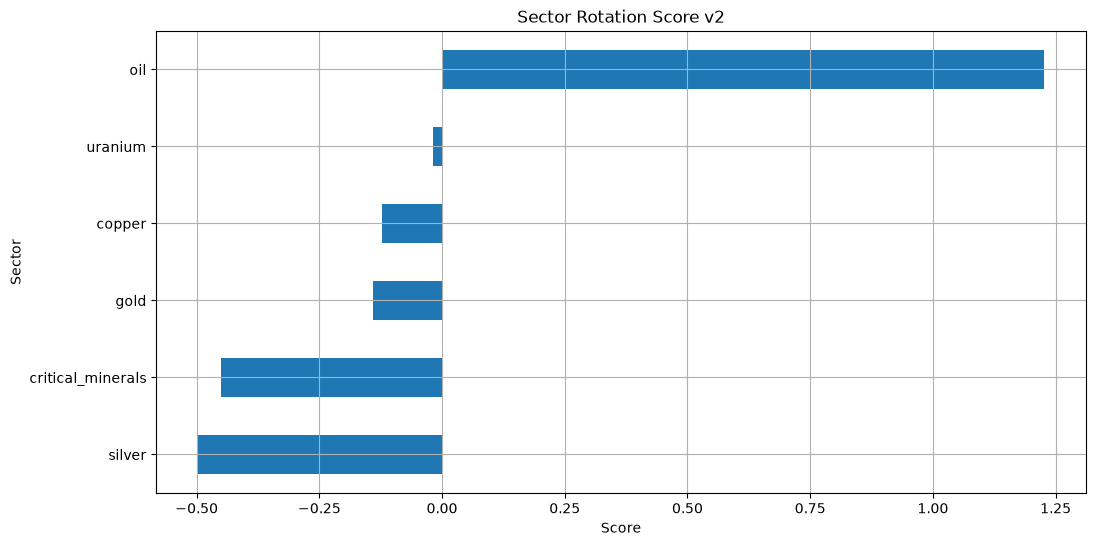

In [18]:
plt.figure(figsize=(12, 6))

(
    rotation_score["rotation_score"]
    .sort_values()
    .plot(kind="barh")
)

plt.title("Sector Rotation Score v2")
plt.xlabel("Score")
plt.ylabel("Sector")
plt.grid(True)
# 保存先のパスを作成
output_path = output_dir / f"sector_rotation_score_v2_{start}_{end}.png"
# 重複するファイルがある場合は削除
if output_path.exists():
    output_path.unlink()
# 保存
plt.savefig(output_path)

plt.show()

#### No.9 現在の買い候補セクター抽出

In [19]:
buy_candidates = rotation_score[
    rotation_score["rotation_score"] > 0
]

buy_candidates


,score20,score60,acceleration,z_score20,z_score60,z_acceleration,rotation_score
oil,0.089958,0.14457,-0.054612,1.894684,1.302719,0.060503,1.226037


#### No.10 個別銘柄スクリーニング

In [20]:
top_sector = rotation_score.index[0]

print("Top Sector")
print(top_sector)

print()
print("Top 3 Sectors")

rotation_score.head(3)


Top Sector
oil

Top 3 Sectors


,score20,score60,acceleration,z_score20,z_score60,z_acceleration,rotation_score
oil,0.089958,0.144570,-0.054612,1.894684,1.302719,0.060503,1.226037
uranium,-0.132921,-0.163980,0.031060,-0.345761,-0.887281,1.109336,-0.017536
copper,-0.120425,-0.069266,-0.051159,-0.220146,-0.215025,0.102774,-0.122246


#### No 11 動作確認

In [21]:
rotation_score

,score20,score60,acceleration,z_score20,z_score60,z_acceleration,rotation_score
oil,0.089958,0.144570,-0.054612,1.894684,1.302719,0.060503,1.226037
uranium,-0.132921,-0.163980,0.031060,-0.345761,-0.887281,1.109336,-0.017536
copper,-0.120425,-0.069266,-0.051159,-0.220146,-0.215025,0.102774,-0.122246
gold,-0.084279,0.078125,-0.162404,0.143204,0.831115,-1.259148,-0.139920
critical_minerals,-0.197899,-0.222871,0.024972,-0.998944,-1.305271,1.034806,-0.450084
silver,-0.145582,-0.000403,-0.145179,-0.473037,0.273742,-1.048271,-0.496251


In [22]:
print(rotation_score)

                    score20   score60  acceleration  z_score20  z_score60  \
oil                0.089958  0.144570     -0.054612   1.894684   1.302719   
uranium           -0.132921 -0.163980      0.031060  -0.345761  -0.887281   
copper            -0.120425 -0.069266     -0.051159  -0.220146  -0.215025   
gold              -0.084279  0.078125     -0.162404   0.143204   0.831115   
critical_minerals -0.197899 -0.222871      0.024972  -0.998944  -1.305271   
silver            -0.145582 -0.000403     -0.145179  -0.473037   0.273742   

                   z_acceleration  rotation_score  
oil                      0.060503        1.226037  
uranium                  1.109336       -0.017536  
copper                   0.102774       -0.122246  
gold                    -1.259148       -0.139920  
critical_minerals        1.034806       -0.450084  
silver                  -1.048271       -0.496251  
